In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from gps_ids import figures
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score


In [2]:
from gps_ids import protocol, training

EXP = protocol.real_heldout("uav")
r = training.run("XGBoost", EXP)
model = r.model
y_pred = r.y_pred
y_test = EXP.y_test
feature_names = EXP.feature_names


mcc=1.0000  balanced_accuracy=1.0000  f1_macro=1.0000  g_mean=1.0000  accuracy=1.0000  majority_baseline_accuracy=0.8621  accuracy_lift_over_majority=0.1379  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/UAVATTACK_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


In [3]:
# Predict and evaluate
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Model Accuracy on Test Set: {accuracy * 100:.2f}%")
print("F1 Score: {:.4f}".format(f1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy on Test Set: 100.00%
F1 Score: 1.0000
Confusion Matrix:
[[625   0]
 [  0 100]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       625
           1       1.00      1.00      1.00       100

    accuracy                           1.00       725
   macro avg       1.00      1.00      1.00       725
weighted avg       1.00      1.00      1.00       725



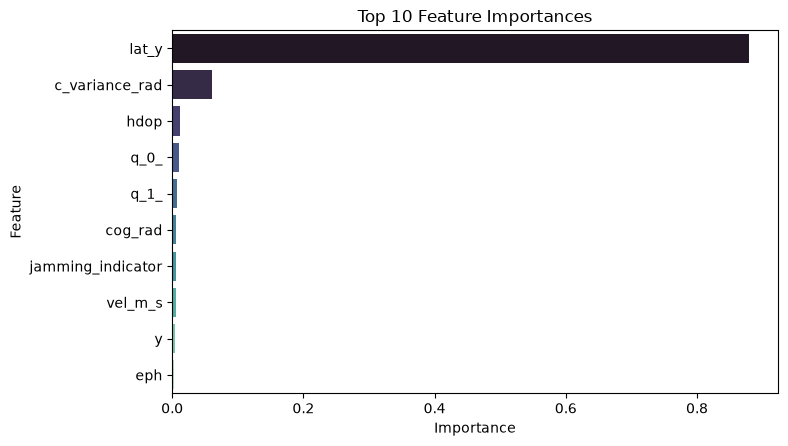

In [4]:
importances = model.feature_importances_

# Create a DataFrame for feature importances
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort by importance descending
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(10),
    x='Importance',
    y='Feature',
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('Top 10 Feature Importances')
plt.tight_layout()
figures.save('feature_importance')
plt.show()

Possibly calculated variance in rad or current, Horizontal dilution of precision, and course over ground are the most important features.

In [5]:
# Seed sweep: the remaining seeds in training.SEEDS, appended to the results CSV.
SWEEP_SEEDS = [s for s in training.SEEDS if s != protocol.SEED]

training.run_seeds("XGBoost", lambda s: protocol.real_heldout("uav", seed=s), seeds=SWEEP_SEEDS)


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


mcc=1.0000  balanced_accuracy=1.0000  f1_macro=1.0000  g_mean=1.0000  accuracy=1.0000  majority_baseline_accuracy=0.8621  accuracy_lift_over_majority=0.1379  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/UAVATTACK_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


mcc=1.0000  balanced_accuracy=1.0000  f1_macro=1.0000  g_mean=1.0000  accuracy=1.0000  majority_baseline_accuracy=0.8621  accuracy_lift_over_majority=0.1379  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/UAVATTACK_Results.csv


mcc=1.0000  balanced_accuracy=1.0000  f1_macro=1.0000  g_mean=1.0000  accuracy=1.0000  majority_baseline_accuracy=0.8621  accuracy_lift_over_majority=0.1379  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/UAVATTACK_Results.csv


mcc=1.0000  balanced_accuracy=1.0000  f1_macro=1.0000  g_mean=1.0000  accuracy=1.0000  majority_baseline_accuracy=0.8621  accuracy_lift_over_majority=0.1379  is_degenerate=False
Results appended to /workspace/project/Image-Based-Intrusion-Detection-System-for-Global-Positioning-System-Spoofing-in-Unmanned-Aerial-Veh/UAVATTACK_Results.csv


/venv/main/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2956: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


[{'model': 'XGBoost',
  'dataset': 'spoofing-merged-gps-only.csv',
  'family': 'Regular',
  'test_set': 'real_heldout_20pct',
  'seed': 7,
  'n_classes': 2,
  'class_names': 'benign;malicious',
  'n_train': 2897,
  'n_test': 725,
  'n_features': 82,
  'mcc': 1.0,
  'balanced_accuracy': 1.0,
  'f1_macro': 1.0,
  'g_mean': 1.0,
  'precision_macro': 1.0,
  'recall_macro': 1.0,
  'accuracy': 1.0,
  'majority_baseline_accuracy': 0.8620689655172413,
  'accuracy_lift_over_majority': 0.13793103448275867,
  'f1_weighted': 1.0,
  'is_degenerate': False,
  'n_classes_predicted': 2,
  'min_class_recall': 1.0,
  'worst_class': 'benign',
  'recall_c0': 1.0,
  'recall_c1': 1.0,
  'recall_c2': 'N/A',
  'recall_c3': 'N/A',
  'precision_c0': 1.0,
  'precision_c1': 1.0,
  'precision_c2': 'N/A',
  'precision_c3': 'N/A',
  'support_c0': 625,
  'support_c1': 100,
  'support_c2': 'N/A',
  'support_c3': 'N/A',
  'train_prior': '0.8626;0.1374',
  'test_prior': '0.8621;0.1379',
  'pred_prior': '0.8621;0.1379',
